# 监督学习

## 分类回归

监督机器学习问题主要有两种：**分类**与**回归**。

- **分类**：预测类别标签。分类问题可分为二分类与多分类。  
- **回归**：预测一个连续值。  

区分分类任务和回归任务，可通过判断其输出是否具有某种连续性，若有则是回归任务。

## 泛化、过拟合与欠拟合

- **泛化**：  

如果一个模型能够对没见过的数据做出准确预测，我们说它能够从训练集泛化到测试集。

- **过拟合**：

构建一个对现有信息量过于复杂的模型。例如在拟合模型时过分关注训练集的细节，则会得到一个在训练集上表现很好，但不能泛化到新数据的模型。

- **欠拟合**：

模型过于简单。例如简单模型无法抓住数据的全部内容以及数据中的变化，在测试集就会表现得很差。

![模型复杂度精度](../res/模型复杂度精度.png '模型复杂度精度')

## 监督学习算法

### 一些数据集

**forge数据集**

X.shape:(26, 2)


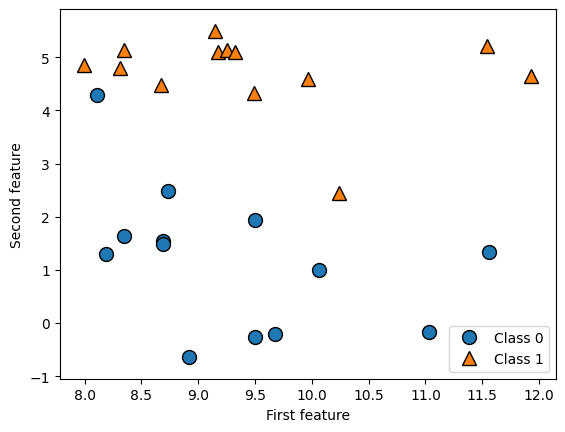

In [3]:
import mglearn
import matplotlib.pyplot as plt
# 生成数据集
X, y = mglearn.datasets.make_forge()
# 数据集绘图
mglearn.discrete_scatter(X[:, 0], X[:, 1], y)
plt.legend(['Class 0', 'Class 1'], loc=4)
plt.xlabel('First feature')
plt.ylabel('Second feature')

print(f'X.shape:{X.shape}')

**wave数据集**

Text(0, 0.5, 'Target')

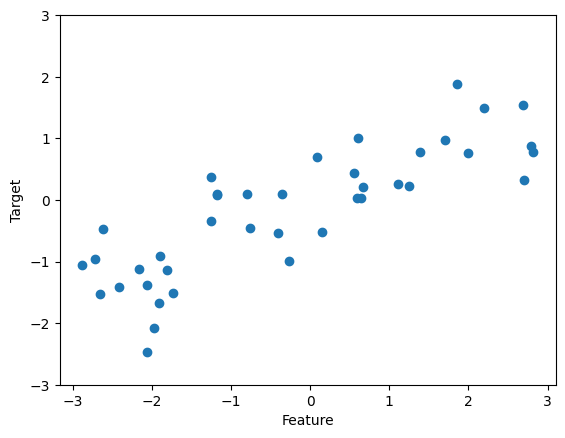

In [5]:
X, y = mglearn.datasets.make_wave(n_samples=40)
plt.plot(X, y, 'o')
plt.ylim(-3, 3)
plt.xlabel('Feature')
plt.ylabel('Target')

**乳腺癌数据集**

In [10]:
from sklearn.datasets import load_breast_cancer
cancer = load_breast_cancer()
print(f'cancer.keys():\n{cancer.keys()}')
print(f'Feature names:\n{cancer.feature_names}')

cancer.keys():
dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])
Feature names:
['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


**房价数据集**（波士顿房价数据被和谐）

In [ ]:
'''from sklearn.datasets import load_boston
boston = load_boston()
print(f'Data shape:\n{boston.data.shape}')'''
import pandas as pd
import numpy as np

data_url = "http://lib.stat.cmu.edu/datasets/boston"
raw_df = pd.read_csv(data_url, sep="\s+", skiprows=22, header=None)
data = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
target = raw_df.values[1::2, 2]

print(f'Data shape: {data.shape}')   # (506, 13)
print(f'Target shape: {target.shape}')  # (506,)

<>:5: SyntaxWarning: invalid escape sequence '\s'
<>:5: SyntaxWarning: invalid escape sequence '\s'
C:\Users\13218\AppData\Local\Temp\ipykernel_15656\3374292122.py:5: SyntaxWarning: invalid escape sequence '\s'
  raw_df = pd.read_csv(data_url, sep="\s+", skiprows=22, header=None)


Data shape: (506, 13)
Target shape: (506,)


**导出特征**

In [16]:
X, y = mglearn.datasets.load_extended_boston()
print(f'X.shape:\n{X.shape}')

X.shape:
(506, 104)


### k近邻

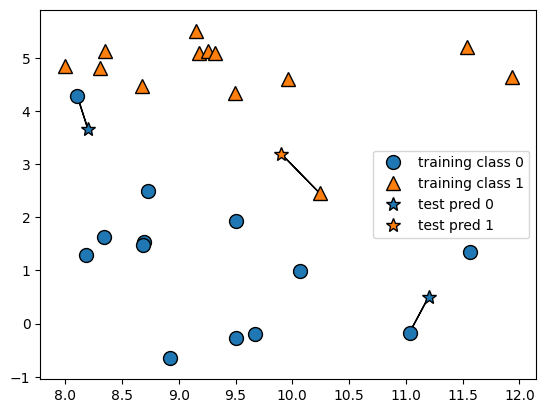

In [ ]:
mglearn.plots.plot_knn_classification(n_neighbors=1) # 五角星代表那些需要进行预测的新数据点，1代表预测最近点数量

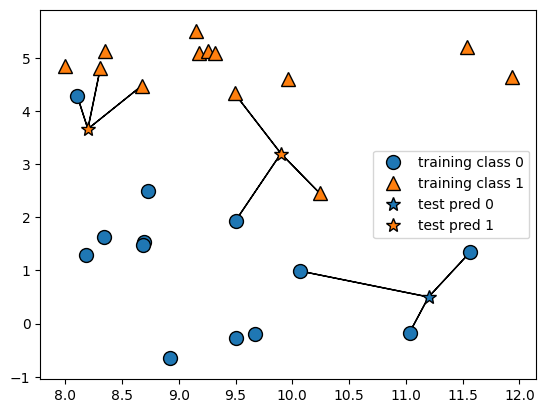

In [19]:
mglearn.plots.plot_knn_classification(n_neighbors=3)

Test set predictions:
[1 0 1 0 1 0 0]
Test set accuracy:0.86


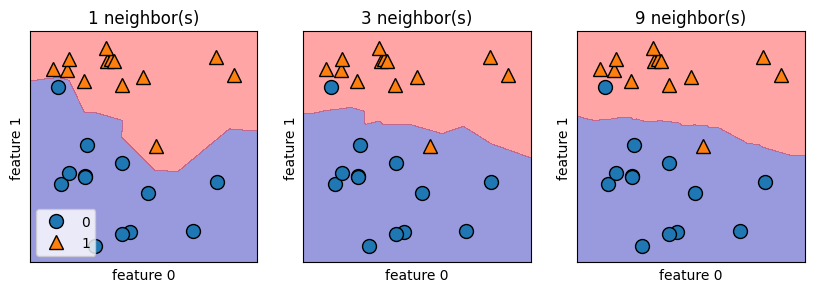

In [27]:
# 分割数据集测试集
from sklearn.model_selection import train_test_split
X,y = mglearn.datasets.make_forge()
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

# 导入并实例化
from sklearn.neighbors import KNeighborsClassifier
clf = KNeighborsClassifier(n_neighbors=3)

# 拟合（保存数据集）
clf.fit(X_train, y_train)

# 调用predict进行预测
print(f'Test set predictions:\n{clf.predict(X_test)}')
print(f'Test set accuracy:{clf.score(X_test, y_test):.2f}')

# 可视化决策边界
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for n_neighbors, ax in zip([1, 3, 9], axes):
    clf = KNeighborsClassifier(n_neighbors=n_neighbors).fit(X, y)
    mglearn.plots.plot_2d_separator(clf, X, fill=True, eps=0.5, ax=ax, alpha=.4)
    mglearn.discrete_scatter(X[:, 0], X[:, 1], y, ax=ax)
    ax.set_title(f'{n_neighbors} neighbor(s)')
    ax.set_xlabel('feature 0')
    ax.set_ylabel('feature 1')
axes[0].legend(loc=3)

不同最近邻数量导致决策边界更平滑

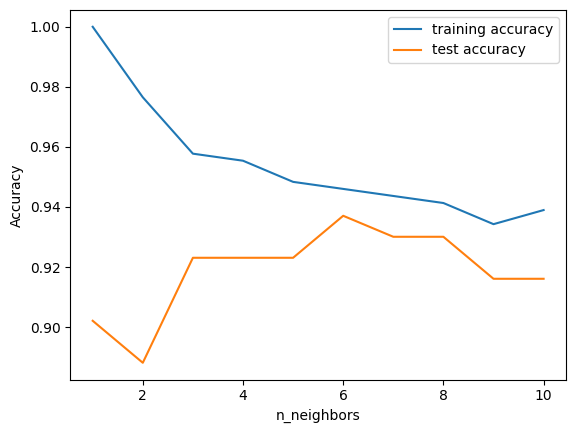

In [ ]:
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(cancer.data, cancer.target, stratify=cancer.target, random_state=66)

training_accuracy = []
test_accuracy = []
neighbors_settings = range(1, 11)

for n_neighbor in neighbors_settings:
    # 构建模型
    clf = KNeighborsClassifier(n_neighbors=n_neighbor)
    clf.fit(X_train, y_train)
    # 记录训练集精度
    training_accuracy.append(clf.score(X_train, y_train))
    # 记录泛化精度
    test_accuracy.append(clf.score(X_test, y_test))

plt.plot(neighbors_settings, training_accuracy, label='training accuracy')
plt.plot(neighbors_settings, test_accuracy, label='test accuracy')
plt.ylabel('Accuracy')
plt.xlabel('n_neighbors')
plt.legend()

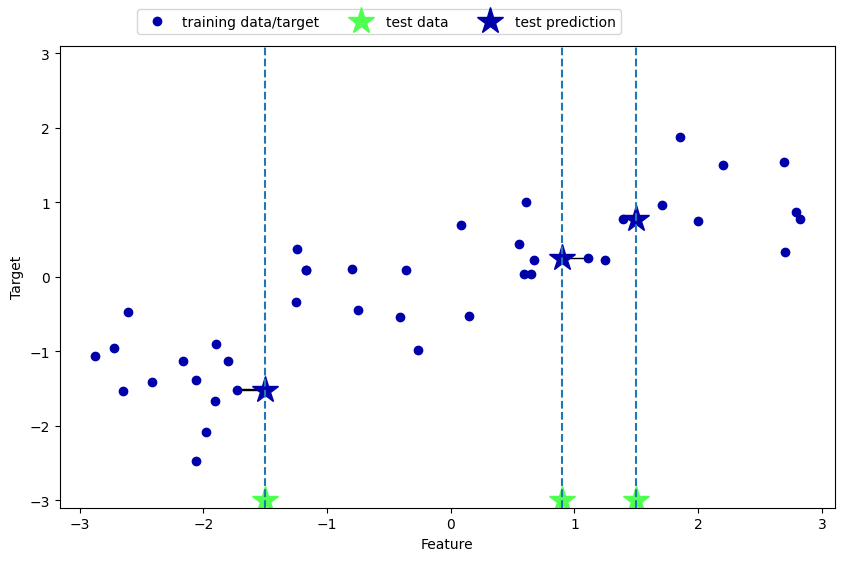

In [33]:
mglearn.plots.plot_knn_regression(n_neighbors=1)

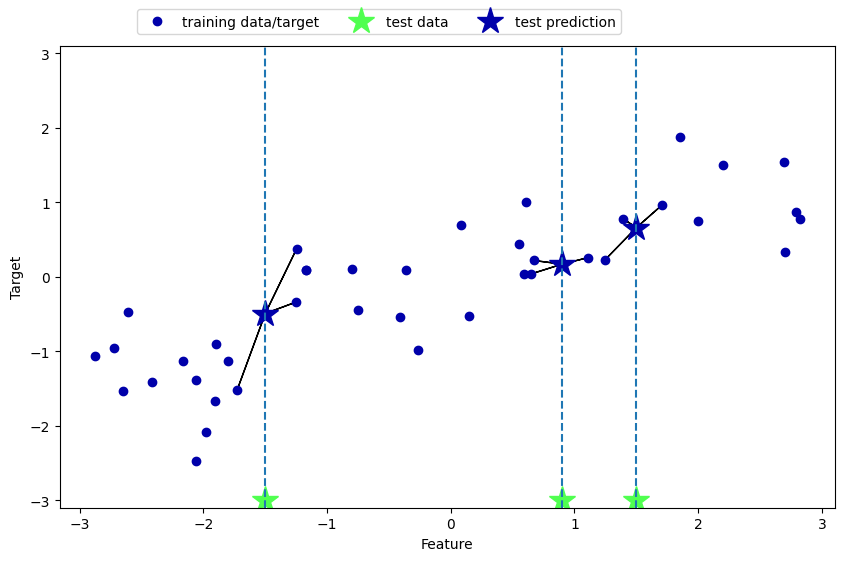

In [32]:
mglearn.plots.plot_knn_regression(n_neighbors=3)